# OLIVE-CAD — Deep Learning & MLOps
## Benchmark reproductible : ResNet50 · EfficientNet-B0 · ConvNeXt-Tiny

**Objectif :** entraîner et comparer trois architectures CNN pour la classification des feuilles d'olivier en trois classes : `aculus_olearius`, `healthy` et `peacock_spot`.

### Pipeline
1. Vérification de l'environnement Kaggle et du GPU
2. Détection du dataset attaché
3. Contrôle des images et provenance des sources
4. Détection de groupes d'images visuellement similaires (pHash)
5. Exclusion documentée des groupes dont les labels sont contradictoires
6. Recréation d'un split **group-aware** Train / Validation / Test
7. DataLoaders, Transfer Learning et Fine-Tuning
8. Tracking des expériences avec MLflow
9. Entraînement séparé des trois modèles
10. Sélection par Macro-F1 de validation, puis test final unique
11. Courbes, matrice de confusion, Grad-CAM, latence et ONNX
12. Export des livrables

> **Protocole anti-fuite :** les groupes d'images similaires restent dans une seule partition. Les groupes contenant des labels contradictoires sont placés en quarantaine (ils restent dans les données brutes/Kaggle, mais ne participent pas au benchmark tant que leurs annotations n'ont pas été vérifiées). Le jeu de test n'est utilisé qu'après la sélection du modèle sur validation.

### Exécution
- Attacher le dataset privé `OLIVE-CAD-Dataset-v1` dans **Add Input**.
- Activer un GPU dans Kaggle.
- Exécuter les cellules dans l'ordre, de haut en bas.
- Chaque étape produit ses propres logs, tableaux ou graphiques.
- Les sorties de cette version sont volontairement vides : elles seront générées avec **cette nouvelle procédure**. Les anciens résultats (obtenus avant le split group-aware) ne sont pas recopiés.

## 0. Environnement et dépendances

In [1]:
# Vérification de compatibilité MLflow / SQLAlchemy pour Kaggle.
# Si une installation est nécessaire, la cellule s'arrête : redémarrer ensuite la session Kaggle.
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError
from packaging.version import Version

to_install = []

try:
    mlflow_v = Version(version("mlflow"))
    if mlflow_v != Version("2.22.0"):
        to_install.append("mlflow==2.22.0")
except PackageNotFoundError:
    to_install.append("mlflow==2.22.0")

try:
    sqlalchemy_v = Version(version("SQLAlchemy"))
    if sqlalchemy_v < Version("2.0") or sqlalchemy_v >= Version("2.1"):
        to_install.append("SQLAlchemy>=2.0,<2.1")
except PackageNotFoundError:
    to_install.append("SQLAlchemy>=2.0,<2.1")

try:
    import cv2
except ImportError:
    to_install.append("opencv-python-headless")

if to_install:
    print("Installation requise :", to_install)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    raise RuntimeError(
        "Dépendances installées. Redémarre la session Kaggle (Run > Restart Session), "
        "puis exécute à nouveau le notebook depuis la première cellule."
    )

print("MLflow :", version("mlflow"))
print("SQLAlchemy :", version("SQLAlchemy"))
print("OpenCV :", __import__("cv2").__version__)
assert Version(version("SQLAlchemy")) < Version("2.1")

MLflow : 2.22.0
SQLAlchemy : 2.0.58
OpenCV : 4.14.0


## 1. Imports et vérification du matériel

In [3]:
import os
import json
import time
import random
import hashlib
import shutil
import zipfile
import warnings
import math
from pathlib import Path
from collections import defaultdict, Counter
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image, ImageOps, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.models import (
    ResNet50_Weights,
    EfficientNet_B0_Weights,
    ConvNeXt_Tiny_Weights,
)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import mlflow
import mlflow.pytorch

warnings.filterwarnings("ignore", category=UserWarning)

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("Torchvision :", __import__("torchvision").__version__)
print("MLflow :", mlflow.__version__)
print("CUDA disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
    print("Nombre de GPU visibles :", torch.cuda.device_count())
else:
    print("ATTENTION : active l'accélérateur GPU dans les paramètres Kaggle.")

Python : 3.13.16
PyTorch : 2.11.0+cu130
Torchvision : 0.26.0+cu130
MLflow : 2.22.0
CUDA disponible : True
GPU : Tesla T4
Nombre de GPU visibles : 2


## 2. Configuration centralisée et reproductibilité

In [4]:
# Modifier les paramètres ici, pas dans les cellules d'entraînement.
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_WORKERS = 2
MAX_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 4

BACKBONE_LR = 1e-4
CLASSIFIER_LR = 5e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.03

USE_PRETRAINED = True
USE_AMP = torch.cuda.is_available()

EXPECTED_CLASSES = {"aculus_olearius", "healthy", "peacock_spot"}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

PHASH_MAX_DISTANCE = 2
GROUP_SPLITS = 20
TEST_FOLDS = 3       # 3/20 ~= 15%
VALIDATION_FOLDS = 3 # 3/20 ~= 15%

KAGGLE_INPUT = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")
OUTPUT_DIR = WORK_DIR / "olive_cad_outputs"
GROUPED_DATASET_DIR = WORK_DIR / "olive_cad_grouped_v1"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Déterminisme autant que possible ; certaines opérations CUDA peuvent rester non déterministes.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", DEVICE)
print("AMP :", USE_AMP)
print("Image size :", IMAGE_SIZE, "| Batch size :", BATCH_SIZE)
print("Epochs maximum :", MAX_EPOCHS, "| Seed :", SEED)

Device : cuda
AMP : True
Image size : 256 | Batch size : 32
Epochs maximum : 15 | Seed : 42


## 3. Détection automatique du dataset Kaggle

Le dataset attendu contient les répertoires de classes sous `train`, `valid` ou `validation`, et `test`. Le code accepte les deux noms `valid` et `validation`.

In [5]:
def count_images(folder):
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

def safe_extract_zip(zip_path, destination):
    """Extraction ZIP sûre : refuse les chemins qui sortent du dossier cible."""
    destination.mkdir(parents=True, exist_ok=True)
    base = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for info in archive.infolist():
            target = (destination / info.filename).resolve()
            if target != base and base not in target.parents:
                raise ValueError(f"Chemin ZIP non sûr : {info.filename}")
        archive.extractall(destination)

def split_dirs_for(parent):
    train_dir = parent / "train"
    test_dir = parent / "test"
    val_dir = next(
        (parent / name for name in ("validation", "valid", "val")
         if (parent / name).is_dir()),
        None
    )
    if train_dir.is_dir() and test_dir.is_dir() and val_dir is not None:
        return {"train": train_dir, "validation": val_dir, "test": test_dir}
    return None

def find_dataset_root(search_roots):
    candidates = []
    seen = set()

    for base in search_roots:
        if not base.exists():
            continue

        for train_dir in base.rglob("train"):
            if not train_dir.is_dir():
                continue

            parent = train_dir.parent
            key = str(parent.resolve())
            if key in seen:
                continue
            seen.add(key)

            split_dirs = split_dirs_for(parent)
            if split_dirs is None:
                continue

            try:
                train_ds = datasets.ImageFolder(str(split_dirs["train"]))
                if len(train_ds) > 0 and len(train_ds.classes) >= 2:
                    total = sum(count_images(p) for p in split_dirs.values())
                    candidates.append((total, parent, split_dirs, train_ds.classes))
            except Exception:
                continue

    if not candidates:
        raise FileNotFoundError(
            "Dataset introuvable. Ajoute OLIVE-CAD-Dataset-v1 dans Kaggle > Add Input. "
            "La structure doit contenir train, validation (ou valid) et test."
        )

    candidates.sort(key=lambda item: item[0], reverse=True)
    return candidates[0][1], candidates[0][2], candidates[0][3], candidates[0][0]

if not KAGGLE_INPUT.exists():
    raise RuntimeError("Ce notebook doit être exécuté dans Kaggle : /kaggle/input absent.")

try:
    DATASET_ROOT, SOURCE_SPLIT_DIRS, discovered_classes, discovered_total = find_dataset_root([KAGGLE_INPUT])
except FileNotFoundError:
    zip_files = list(KAGGLE_INPUT.rglob("*.zip"))
    if not zip_files:
        raise
    EXTRACT_DIR = WORK_DIR / "olive_cad_dataset_extracted"
    for zip_path in zip_files:
        print("Extraction :", zip_path)
        safe_extract_zip(zip_path, EXTRACT_DIR)
    DATASET_ROOT, SOURCE_SPLIT_DIRS, discovered_classes, discovered_total = find_dataset_root([EXTRACT_DIR])

print("Dataset root :", DATASET_ROOT)
print("Classes découvertes :", discovered_classes)
print("Images détectées :", discovered_total)
for split_name, split_path in SOURCE_SPLIT_DIRS.items():
    print(f"{split_name:12s}: {count_images(split_path)} images")

if set(discovered_classes) != EXPECTED_CLASSES:
    raise ValueError(
        f"Classes attendues : {sorted(EXPECTED_CLASSES)} ; "
        f"trouvées : {discovered_classes}. Vérifie le dataset attaché."
    )

Dataset root : /kaggle/input/datasets/kenzayahiaoui/olive-cad-dataset-v1/olive_cad_v1
Classes découvertes : ['aculus_olearius', 'healthy', 'peacock_spot']
Images détectées : 4565
train       : 3195 images
validation  : 685 images
test        : 685 images


## 4. Inventaire initial et contrôle d'intégrité

In [6]:
source_datasets = {
    split: datasets.ImageFolder(str(folder))
    for split, folder in SOURCE_SPLIT_DIRS.items()
}

class_names = source_datasets["train"].classes
class_to_idx = source_datasets["train"].class_to_idx

if set(class_names) != EXPECTED_CLASSES:
    raise ValueError(f"Classes inattendues : {class_names}")

records = []
corrupt_files = []

for split, dataset in source_datasets.items():
    if dataset.classes != class_names:
        raise ValueError(f"Classes incohérentes dans {split}.")

    for path, label_idx in dataset.samples:
        image_path = Path(path)
        try:
            with Image.open(image_path) as image:
                image.verify()
        except Exception as exc:
            corrupt_files.append((str(image_path), str(exc)))
            continue

        filename = image_path.name.lower()
        if filename.startswith("source_a_"):
            source = "SOURCE_A"
        elif filename.startswith("source_c_"):
            source = "SOURCE_C"
        else:
            source = "UNKNOWN"

        records.append({
            "path": str(image_path.resolve()),
            "label": class_names[label_idx],
            "label_idx": label_idx,
            "original_split": split,
            "source": source,
        })

if corrupt_files:
    pd.DataFrame(corrupt_files, columns=["file", "error"]).to_csv(
        OUTPUT_DIR / "corrupt_images.csv", index=False
    )
    raise RuntimeError(
        f"{len(corrupt_files)} images illisibles. Rapport : "
        f"{OUTPUT_DIR / 'corrupt_images.csv'}"
    )

inventory = pd.DataFrame(records)
print("Images lisibles :", len(inventory))
print("Images corrompues : 0")
print("\nRépartition initiale :")
display(pd.crosstab(inventory["original_split"], inventory["label"]))
print("\nProvenance :")
display(pd.crosstab(inventory["source"], inventory["label"]))
inventory.to_csv(OUTPUT_DIR / "initial_inventory.csv", index=False)

Images lisibles : 4565
Images corrompues : 0

Répartition initiale :


label,aculus_olearius,healthy,peacock_spot
original_split,,,
test,62,411,212
train,293,1917,985
validation,63,411,211



Provenance :


label,aculus_olearius,healthy,peacock_spot
source,,,
SOURCE_A,0,572,382
SOURCE_C,418,2167,1026


## 5. Détection des images similaires et regroupement pHash

Le pHash repère des images visuellement proches, mais ne prouve pas à lui seul qu'il s'agit de doublons. Nous utilisons un seuil strict configurable (distance de Hamming ≤ 2). Les paires de classes différentes sont signalées ; les groupes contenant plusieurs labels sont mis en quarantaine pour éviter d'entraîner le modèle sur des annotations potentiellement contradictoires.

In [7]:
def calculate_phash(image_path):
    """pHash 64 bits basé sur la DCT."""
    with Image.open(image_path) as image:
        gray = image.convert("L").resize((32, 32), Image.Resampling.LANCZOS)
    pixels = np.asarray(gray, dtype=np.float32)
    dct = cv2.dct(pixels)
    low = dct[:8, :8].flatten()
    median = np.median(low[1:])
    bits = low > median

    value = 0
    for bit_index, bit in enumerate(bits):
        if bool(bit):
            value |= (1 << bit_index)
    return np.uint64(value)

print("Calcul des empreintes pHash...")
phash_values = np.empty(len(records), dtype=np.uint64)

for idx, row in enumerate(records):
    phash_values[idx] = calculate_phash(row["path"])
    if (idx + 1) % 500 == 0 or idx + 1 == len(records):
        print(f"{idx + 1}/{len(records)}")

# Union-Find pour former des groupes transitifs.
parent = list(range(len(records)))

def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union_groups(a, b):
    ra, rb = find_root(a), find_root(b)
    if ra != rb:
        parent[rb] = ra

# Recherche vectorisée par blocs pour limiter l'usage mémoire.
popcount = np.array([int(i).bit_count() for i in range(256)], dtype=np.uint8)
near_pairs = []
n_images = len(records)
block_size = 128

for start in range(0, n_images, block_size):
    end = min(start + block_size, n_images)
    xor_block = np.bitwise_xor(
        phash_values[start:end, None],
        phash_values[None, :]
    )
    byte_block = xor_block.view(np.uint8).reshape(end - start, n_images, 8)
    distances = popcount[byte_block].sum(axis=2)

    for local_idx, global_idx in enumerate(range(start, end)):
        candidates = np.flatnonzero(
            (distances[local_idx] <= PHASH_MAX_DISTANCE)
            & (np.arange(n_images) > global_idx)
        )
        for other_idx in candidates:
            distance = int(distances[local_idx, other_idx])
            union_groups(global_idx, int(other_idx))
            near_pairs.append({
                "image_1": records[global_idx]["path"],
                "image_2": records[other_idx]["path"],
                "label_1": records[global_idx]["label"],
                "label_2": records[other_idx]["label"],
                "source_1": records[global_idx]["source"],
                "source_2": records[other_idx]["source"],
                "original_split_1": records[global_idx]["original_split"],
                "original_split_2": records[other_idx]["original_split"],
                "distance": distance,
            })

# Identifiants de groupes
group_roots = [find_root(i) for i in range(n_images)]
root_to_group = {root: idx for idx, root in enumerate(sorted(set(group_roots)))}
group_ids = np.array([root_to_group[root] for root in group_roots])

group_label_map = defaultdict(set)
for idx, group_id in enumerate(group_ids):
    group_label_map[int(group_id)].add(records[idx]["label"])

conflicting_group_ids = {
    group_id for group_id, labels in group_label_map.items()
    if len(labels) > 1
}

pairs_df = pd.DataFrame(near_pairs)
pairs_path = OUTPUT_DIR / "near_duplicate_candidates.csv"
pairs_df.to_csv(pairs_path, index=False)

group_audit = pd.DataFrame([
    {
        "group_id": group_id,
        "labels": ";".join(sorted(labels)),
        "n_images": int(np.sum(group_ids == group_id)),
        "label_conflict": len(labels) > 1,
    }
    for group_id, labels in group_label_map.items()
])
group_audit.to_csv(OUTPUT_DIR / "phash_group_audit.csv", index=False)

print("Images analysées :", n_images)
print("Paires pHash candidates :", len(near_pairs))
print("Groupes de similarité :", len(group_label_map))
print("Groupes avec labels contradictoires :", len(conflicting_group_ids))
print("Rapports :", pairs_path, "et", OUTPUT_DIR / "phash_group_audit.csv")

if len(near_pairs):
    display(pairs_df["distance"].value_counts().sort_index().rename("pair_count").to_frame())
    display(group_audit[group_audit["label_conflict"]].head(20))
else:
    print("Aucune paire sous le seuil pHash configuré.")

Calcul des empreintes pHash...
500/4565
1000/4565
1500/4565
2000/4565
2500/4565
3000/4565
3500/4565
4000/4565
4500/4565
4565/4565
Images analysées : 4565
Paires pHash candidates : 77
Groupes de similarité : 4489
Groupes avec labels contradictoires : 19
Rapports : /kaggle/working/olive_cad_outputs/near_duplicate_candidates.csv et /kaggle/working/olive_cad_outputs/phash_group_audit.csv


,pair_count
distance,
0,3
2,74


,group_id,labels,n_images,label_conflict
303,303,healthy;peacock_spot,4,True
397,396,healthy;peacock_spot,2,True
474,473,healthy;peacock_spot,2,True
479,478,healthy;peacock_spot,2,True
589,589,healthy;peacock_spot,2,True
606,606,healthy;peacock_spot,2,True
636,636,healthy;peacock_spot,2,True
678,678,healthy;peacock_spot,3,True
704,704,healthy;peacock_spot,4,True
1125,1125,healthy;peacock_spot,2,True


## 6. Split group-aware et quarantaine des labels contradictoires

Les groupes pHash sont indivisibles : toutes les images d'un groupe vont dans la même partition. Les groupes de labels contradictoires sont exclus du benchmark et enregistrés séparément pour revue manuelle ; les fichiers originaux ne sont pas supprimés.

In [8]:
# Exclure du benchmark les groupes dont les images proches ont des étiquettes différentes.
eligible_indices = [
    idx for idx, group_id in enumerate(group_ids)
    if int(group_id) not in conflicting_group_ids
]
quarantined_indices = [
    idx for idx, group_id in enumerate(group_ids)
    if int(group_id) in conflicting_group_ids
]

quarantine_df = pd.DataFrame([
    {
        **records[idx],
        "group_id": int(group_ids[idx]),
        "reason": "phash_group_contains_multiple_labels",
    }
    for idx in quarantined_indices
])
quarantine_df.to_csv(OUTPUT_DIR / "quarantined_label_conflicts.csv", index=False)

if not eligible_indices:
    raise RuntimeError("Toutes les images ont été mises en quarantaine.")

y_eligible = np.array([records[idx]["label_idx"] for idx in eligible_indices])
groups_eligible = group_ids[eligible_indices]

class_group_counts = {
    class_name: len({
        int(groups_eligible[i])
        for i, global_idx in enumerate(eligible_indices)
        if records[global_idx]["label"] == class_name
    })
    for class_name in class_names
}
print("Groupes disponibles par classe :", class_group_counts)

if min(class_group_counts.values()) < GROUP_SPLITS:
    raise ValueError(
        f"Pas assez de groupes distincts pour {GROUP_SPLITS} folds : "
        f"{class_group_counts}. Réduis GROUP_SPLITS."
    )

splitter = StratifiedGroupKFold(
    n_splits=GROUP_SPLITS,
    shuffle=True,
    random_state=SEED,
)

assignments = {}
for fold_idx, (_, held_out_idx) in enumerate(
    splitter.split(
        np.zeros(len(eligible_indices)),
        y_eligible,
        groups_eligible,
    )
):
    if fold_idx < TEST_FOLDS:
        split_name = "test"
    elif fold_idx < TEST_FOLDS + VALIDATION_FOLDS:
        split_name = "validation"
    else:
        split_name = "train"

    for local_idx in held_out_idx:
        global_idx = eligible_indices[int(local_idx)]
        assignments[global_idx] = split_name

if len(assignments) != len(eligible_indices):
    raise RuntimeError("Certaines images n'ont pas reçu de partition.")

# Construire le nouveau dataset dans /kaggle/working.
if GROUPED_DATASET_DIR.exists():
    shutil.rmtree(GROUPED_DATASET_DIR)

manifest_rows = []
for global_idx in eligible_indices:
    record = records[global_idx]
    split_name = assignments[global_idx]
    group_id = int(group_ids[global_idx])
    source_prefix = record["source"].lower()

    original_path = Path(record["path"])
    output_name = f"{source_prefix}_{global_idx:05d}_{original_path.name}"
    destination = (
        GROUPED_DATASET_DIR / split_name / record["label"] / output_name
    )
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(original_path, destination)

    manifest_rows.append({
        "split": split_name,
        "label": record["label"],
        "source": record["source"],
        "original_split": record["original_split"],
        "group_id": group_id,
        "image_path": destination.relative_to(GROUPED_DATASET_DIR).as_posix(),
    })

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(GROUPED_DATASET_DIR / "manifest.csv", index=False)

# Vérification anti-fuite : un groupe ne doit exister que dans un seul split.
group_split_count = manifest.groupby("group_id")["split"].nunique()
assert group_split_count.max() == 1, "Un groupe de similarité traverse les partitions."

split_table = pd.crosstab(manifest["split"], manifest["label"]).reindex(
    index=["train", "validation", "test"],
    columns=class_names,
    fill_value=0,
)
display(split_table)

print("Images retenues :", len(manifest))
print("Images en quarantaine :", len(quarantine_df))
print("Proportions :")
display((manifest["split"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())
print("Groupes inter-partitions :", int((group_split_count > 1).sum()))
print("Nouveau dataset :", GROUPED_DATASET_DIR)
print("Rapport quarantaine :", OUTPUT_DIR / "quarantined_label_conflicts.csv")

split_table.to_csv(OUTPUT_DIR / "grouped_split_distribution.csv")

Groupes disponibles par classe : {'aculus_olearius': 415, 'healthy': 2675, 'peacock_spot': 1380}


label,aculus_olearius,healthy,peacock_spot
split,,,
train,291,1902,975
validation,63,409,206
test,63,404,209


Images retenues : 4522
Images en quarantaine : 43
Proportions :


,percent
split,
train,70.06
validation,14.99
test,14.95


Groupes inter-partitions : 0
Nouveau dataset : /kaggle/working/olive_cad_grouped_v1
Rapport quarantaine : /kaggle/working/olive_cad_outputs/quarantined_label_conflicts.csv


## 7. Chargement des nouvelles partitions et contrôle final

In [9]:
DATASET_ROOT = GROUPED_DATASET_DIR
SPLIT_NAMES = ("train", "validation", "test")

raw_datasets = {
    split: datasets.ImageFolder(str(DATASET_ROOT / split))
    for split in SPLIT_NAMES
}
class_names = raw_datasets["train"].classes
class_to_idx = raw_datasets["train"].class_to_idx

if set(class_names) != EXPECTED_CLASSES:
    raise ValueError(f"Classes incorrectes après split : {class_names}")

for split, dataset in raw_datasets.items():
    if dataset.classes != class_names:
        raise ValueError(f"Mapping de classes incohérent dans {split}.")
    if len(dataset) == 0:
        raise ValueError(f"Partition vide : {split}")

final_counts = pd.DataFrame({
    split: Counter(class_names[label] for _, label in dataset.samples)
    for split, dataset in raw_datasets.items()
}).T.reindex(index=SPLIT_NAMES, columns=class_names, fill_value=0)

print("DATASET FINAL")
display(final_counts)
print("Total :", int(final_counts.to_numpy().sum()))
print("Class mapping :", class_to_idx)

DATASET FINAL


,aculus_olearius,healthy,peacock_spot
train,291,1902,975
validation,63,409,206
test,63,404,209


Total : 4522
Class mapping : {'aculus_olearius': 0, 'healthy': 1, 'peacock_spot': 2}


## 8. Prétraitement et augmentations

Toutes les images sont converties en RGB, redimensionnées en conservant leurs proportions puis placées sur un canevas carré blanc (*letterboxing*). Les augmentations ne sont appliquées qu'à Train ; Validation et Test restent déterministes.

In [10]:
class SquarePadResize:
    """Redimensionnement proportionnel + padding blanc, sans étirement."""
    def __init__(self, size=IMAGE_SIZE, fill=(255, 255, 255)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        contained = ImageOps.contain(
            image, (self.size, self.size), method=Image.Resampling.LANCZOS
        )
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        x = (self.size - contained.width) // 2
        y = (self.size - contained.height) // 2
        canvas.paste(contained, (x, y))
        return canvas

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    SquarePadResize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8, fill=(255, 255, 255)),
    transforms.ColorJitter(
        brightness=0.08, contrast=0.08, saturation=0.06, hue=0.01
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    SquarePadResize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(DATASET_ROOT / "train", transform=train_transform)
val_dataset = datasets.ImageFolder(DATASET_ROOT / "validation", transform=eval_transform)
test_dataset = datasets.ImageFolder(DATASET_ROOT / "test", transform=eval_transform)

assert train_dataset.classes == val_dataset.classes == test_dataset.classes == class_names
print("Transformations prêtes.")
print("Train :", len(train_dataset), "| Validation :", len(val_dataset), "| Test :", len(test_dataset))

Transformations prêtes.
Train : 3168 | Validation : 678 | Test : 676


## 9. DataLoaders et gestion du déséquilibre

In [11]:
# ============================================================
# OLIVE-CAD — DataLoaders & Class Imbalance Management
# Stable configuration for Kaggle
# ============================================================

# Stable settings
NUM_WORKERS = 0
PIN_MEMORY = False

# Reproducibility
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=loader_generator,
    drop_last=False
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

# Test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

# ============================================================
# CLASS WEIGHTS — Handle class imbalance
# ============================================================

train_targets = np.array([
    label for _, label in train_dataset.samples
])

class_counts = np.bincount(
    train_targets,
    minlength=len(class_names)
)

if np.any(class_counts == 0):
    raise ValueError("Une classe n'a aucun exemple dans Train.")

class_weights = len(train_targets) / (
    len(class_names) * class_counts.astype(np.float64)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

# ============================================================
# SUMMARY
# ============================================================

print("=" * 55)
print("OLIVE-CAD — DATALOADER CONFIGURATION")
print("=" * 55)

print("Device:", DEVICE)
print("Number of workers:", NUM_WORKERS)
print("Pin memory:", PIN_MEMORY)
print("Batch size:", BATCH_SIZE)

print("\nClass distribution:")
for name, count, weight in zip(
    class_names,
    class_counts,
    class_weights
):
    print(f"{name:20s}: {count:5d} images | weight: {weight:.4f}")

print("\nNumber of batches:")
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

print("\nDataLoaders initialized successfully!")

OLIVE-CAD — DATALOADER CONFIGURATION
Device: cuda
Number of workers: 0
Pin memory: False
Batch size: 32

Class distribution:
aculus_olearius     :   291 images | weight: 3.6289
healthy             :  1902 images | weight: 0.5552
peacock_spot        :   975 images | weight: 1.0831

Number of batches:
Train: 99
Validation: 22
Test: 22

DataLoaders initialized successfully!


In [12]:
images, labels = next(iter(train_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Device:", DEVICE)

assert images.shape[0] > 0
assert labels.shape[0] == images.shape[0]

print("DataLoader test: SUCCESS")

Batch shape: torch.Size([32, 3, 256, 256])
Labels shape: torch.Size([32])
Device: cuda
DataLoader test: SUCCESS


## 10. Aperçu des images après prétraitement

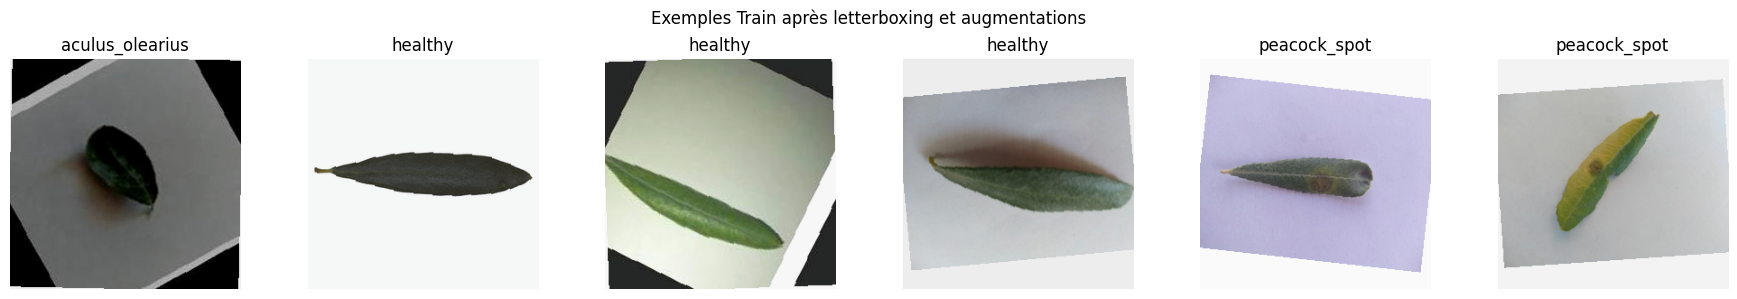

In [13]:
def show_training_samples(dataset, n=6):
    n = min(n, len(dataset))
    indices = np.linspace(0, len(dataset) - 1, n, dtype=int)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    axes = np.atleast_1d(axes)

    for ax, idx in zip(axes, indices):
        tensor, label = dataset[idx]
        image = tensor.permute(1, 2, 0).numpy()
        image = image * np.asarray(IMAGENET_STD) + np.asarray(IMAGENET_MEAN)
        ax.imshow(np.clip(image, 0, 1))
        ax.set_title(class_names[label])
        ax.axis("off")

    plt.suptitle("Exemples Train après letterboxing et augmentations")
    plt.tight_layout()
    plt.show()

show_training_samples(train_dataset)

## 11. MLflow — initialisation du suivi

In [14]:
EXPERIMENT_NAME = "OLIVE-CAD-Grouped-v1-Three-CNN"
MLFLOW_DB = WORK_DIR / "olive_cad_mlflow.db"
MLFLOW_ARTIFACTS = WORK_DIR / "olive_cad_mlflow_artifacts"
MLFLOW_ARTIFACTS.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

existing = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
if existing is None:
    mlflow.create_experiment(
        EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACTS.resolve().as_uri(),
    )
mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Experiment :", EXPERIMENT_NAME)
print("Database :", MLFLOW_DB)

2026/11/17 20:03:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 20:03:56 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Running upgrade  -> 451aebb31d03, add metric step
INFO  [alembic.runtime.migration] Running upgrade 451aebb31d03 -> 90e64c465722, migrate user column to tags
INFO  [alembic.runtime.migration] Running upgrade 90e64c465722 -> 181f10493468, allow nulls for metric values
INFO  [alembic.runtime.migration] Running upgrade 181f10493468 -> df50e92ffc5e, Add Experiment Tags Table
INFO  [alembic.runtime.migration] Running upgrade df50e92ffc5e -> 7ac759974ad8, Update run tags with larger limit
INFO  [alembic.runtime.migration] Running upgrade 7ac759974ad8 -> 89d4b8295536, create latest metrics table
INFO  [89d4b8295536_create_latest_metrics_table_py] Migration complete!
INFO  

Tracking URI : sqlite:////kaggle/working/olive_cad_mlflow.db
Experiment : OLIVE-CAD-Grouped-v1-Three-CNN
Database : /kaggle/working/olive_cad_mlflow.db


## 12. Configuration commune des expériences

In [15]:
CONFIG = {
    "project": "OLIVE-CAD",
    "dataset_version": "grouped_v1",
    "split_method": "StratifiedGroupKFold",
    "phash_max_distance": PHASH_MAX_DISTANCE,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "pretrained": USE_PRETRAINED,
    "classes": ",".join(class_names),
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "test_images": len(test_dataset),
    "device": str(DEVICE),
    "amp": USE_AMP,
}
with open(OUTPUT_DIR / "training_config.json", "w", encoding="utf-8") as file:
    json.dump(CONFIG, file, indent=2, ensure_ascii=False)

print("Configuration enregistrée.")
display(pd.DataFrame([CONFIG]).T.rename(columns={0: "value"}))

Configuration enregistrée.


,value
project,OLIVE-CAD
dataset_version,grouped_v1
split_method,StratifiedGroupKFold
phash_max_distance,2
seed,42
image_size,256
batch_size,32
max_epochs,15
early_stopping_patience,4
backbone_lr,0.0001


## 13. Architectures : ResNet50, EfficientNet-B0 et ConvNeXt-Tiny

In [16]:
def build_model(model_name, num_classes=len(class_names), pretrained=USE_PRETRAINED):
    """Construit un modèle torchvision et sépare les paramètres backbone / tête."""
    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.25), nn.Linear(in_features, num_classes))
        head_prefix = "fc."

    elif model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Sequential(
            nn.Dropout(0.25), nn.Linear(in_features, num_classes)
        )
        head_prefix = "classifier."

    elif model_name == "convnext_tiny":
        weights = ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        model = models.convnext_tiny(weights=weights)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(0.30), nn.Linear(in_features, num_classes)
        )
        head_prefix = "classifier."

    else:
        raise ValueError(f"Architecture inconnue : {model_name}")

    backbone_params, head_params = [], []
    for name, parameter in model.named_parameters():
        if name.startswith(head_prefix):
            head_params.append(parameter)
        else:
            backbone_params.append(parameter)

    return model, backbone_params, head_params

for architecture in ("resnet50", "efficientnet_b0", "convnext_tiny"):
    test_model, backbone_params, head_params = build_model(architecture)
    total_params = sum(p.numel() for p in test_model.parameters())
    trainable_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
    print(
        f"{architecture:16s} | total={total_params:,} "
        f"| trainable={trainable_params:,} "
        f"| backbone={sum(p.numel() for p in backbone_params):,} "
        f"| head={sum(p.numel() for p in head_params):,}"
    )
    del test_model, backbone_params, head_params

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 223MB/s] 


resnet50         | total=23,514,179 | trainable=23,514,179 | backbone=23,508,032 | head=6,147
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 


efficientnet_b0  | total=4,011,391 | trainable=4,011,391 | backbone=4,007,548 | head=3,843
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 214MB/s]  


convnext_tiny    | total=27,822,435 | trainable=27,822,435 | backbone=27,818,592 | head=3,843


## 14. Fonctions communes : métriques, entraînement et validation

In [17]:
def autocast_context():
    if USE_AMP:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def calculate_metrics(y_true, y_pred):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(len(class_names))),
        average="macro", zero_division=0
    )
    weighted_f1 = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(len(class_names))),
        average="weighted", zero_division=0
    )[2]
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
    }

def run_train_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    total_loss = 0.0
    y_true, y_pred = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(logits.detach().argmax(dim=1).cpu().tolist())

    metrics = calculate_metrics(y_true, y_pred)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics

@torch.no_grad()
def run_evaluation(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    y_true, y_pred, probabilities = [], [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, labels)

        probs = torch.softmax(logits.float(), dim=1)
        total_loss += loss.item() * labels.size(0)
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().tolist())
        probabilities.extend(probs.cpu().tolist())

    metrics = calculate_metrics(y_true, y_pred)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics, np.asarray(y_true), np.asarray(y_pred), np.asarray(probabilities)

print("Fonctions d'entraînement et d'évaluation prêtes.")

Fonctions d'entraînement et d'évaluation prêtes.


## 15. Fonction d'entraînement avec MLflow et Early Stopping

In [18]:
import random
import numpy as np
import torch

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("seed_everything prête.")

seed_everything prête.


In [19]:
def train_model(model_name):
    print(f"\n{'=' * 72}\nDÉBUT : {model_name}\n{'=' * 72}")
    seed_everything(SEED)

    model, backbone_params, head_params = build_model(model_name)
    model = model.to(DEVICE)

    optimizer = optim.AdamW(
        [
            {"params": backbone_params, "lr": BACKBONE_LR},
            {"params": head_params, "lr": CLASSIFIER_LR},
        ],
        weight_decay=WEIGHT_DECAY,
    )
    criterion = nn.CrossEntropyLoss(
        weight=class_weights_tensor,
        label_smoothing=LABEL_SMOOTHING,
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2, min_lr=1e-7
    )
    scaler = make_grad_scaler()

    best_f1 = -1.0
    best_epoch = 0
    patience_counter = 0
    history = []
    checkpoint_path = OUTPUT_DIR / f"best_{model_name}.pth"
    start_time = time.perf_counter()

    with mlflow.start_run(run_name=model_name) as run:
        params = {
            **CONFIG,
            "architecture": model_name,
            "optimizer": "AdamW",
            "loss": "class_weighted_cross_entropy",
        }
        mlflow.log_params({
            key: (str(value) if isinstance(value, (list, dict)) else value)
            for key, value in params.items()
        })

        for epoch in range(1, MAX_EPOCHS + 1):
            epoch_start = time.perf_counter()

            train_metrics = run_train_epoch(
                model, train_loader, criterion, optimizer, scaler
            )
            val_metrics, _, _, _ = run_evaluation(
                model, val_loader, criterion
            )
            scheduler.step(val_metrics["macro_f1"])
            epoch_seconds = time.perf_counter() - epoch_start

            row = {
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
                "epoch_seconds": epoch_seconds,
                "backbone_lr": optimizer.param_groups[0]["lr"],
                "classifier_lr": optimizer.param_groups[1]["lr"],
            }
            history.append(row)

            for key, value in row.items():
                if key != "epoch":
                    mlflow.log_metric(key, float(value), step=epoch)

            print(
                f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
                f"train_loss={train_metrics['loss']:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"val_macro_f1={val_metrics['macro_f1']:.4f} | "
                f"val_accuracy={val_metrics['accuracy']:.4f} | "
                f"{epoch_seconds:.1f}s"
            )

            if val_metrics["macro_f1"] > best_f1 + 1e-4:
                best_f1 = val_metrics["macro_f1"]
                best_epoch = epoch
                patience_counter = 0

                torch.save({
                    "architecture": model_name,
                    "state_dict": {
                        key: value.detach().cpu()
                        for key, value in model.state_dict().items()
                    },
                    "class_names": class_names,
                    "class_to_idx": class_to_idx,
                    "image_size": IMAGE_SIZE,
                    "imagenet_mean": IMAGENET_MEAN,
                    "imagenet_std": IMAGENET_STD,
                    "best_epoch": best_epoch,
                    "best_val_macro_f1": best_f1,
                    "config": CONFIG,
                }, checkpoint_path)
            else:
                patience_counter += 1

            if patience_counter >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping après {epoch} epochs.")
                break

        training_seconds = time.perf_counter() - start_time
        history_df = pd.DataFrame(history)
        history_path = OUTPUT_DIR / f"history_{model_name}.csv"
        history_df.to_csv(history_path, index=False)

        mlflow.log_metric("best_val_macro_f1", best_f1)
        mlflow.log_metric("best_epoch", best_epoch)
        mlflow.log_metric("training_seconds", training_seconds)
        mlflow.log_artifact(str(checkpoint_path))
        mlflow.log_artifact(str(history_path))

        run_id = run.info.run_id

    print(f"Meilleur validation Macro-F1 : {best_f1:.4f} (epoch {best_epoch})")
    print(f"Durée : {training_seconds / 60:.1f} min | Run ID : {run_id}")

    del model, optimizer, scaler
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "model_name": model_name,
        "best_val_macro_f1": best_f1,
        "best_epoch": best_epoch,
        "training_seconds": training_seconds,
        "checkpoint": str(checkpoint_path),
        "history_path": str(history_path),
        "run_id": run_id,
    }

print("Fonction train_model prête.")

Fonction train_model prête.


## 16. Entraînement 1/3 — ResNet50

In [20]:
result_resnet50 = train_model("resnet50")
display(pd.DataFrame([result_resnet50]))


DÉBUT : resnet50
Epoch 01/15 | train_loss=0.4964 | val_loss=0.3284 | val_macro_f1=0.9700 | val_accuracy=0.9794 | 81.6s
Epoch 02/15 | train_loss=0.2820 | val_loss=0.3197 | val_macro_f1=0.9672 | val_accuracy=0.9764 | 75.7s
Epoch 03/15 | train_loss=0.2400 | val_loss=0.3374 | val_macro_f1=0.9583 | val_accuracy=0.9735 | 76.7s
Epoch 04/15 | train_loss=0.2496 | val_loss=0.3562 | val_macro_f1=0.9464 | val_accuracy=0.9676 | 76.4s
Epoch 05/15 | train_loss=0.2110 | val_loss=0.3118 | val_macro_f1=0.9795 | val_accuracy=0.9823 | 76.0s
Epoch 06/15 | train_loss=0.2124 | val_loss=0.3105 | val_macro_f1=0.9816 | val_accuracy=0.9853 | 76.7s
Epoch 07/15 | train_loss=0.2069 | val_loss=0.3257 | val_macro_f1=0.9683 | val_accuracy=0.9794 | 76.4s
Epoch 08/15 | train_loss=0.2041 | val_loss=0.3033 | val_macro_f1=0.9868 | val_accuracy=0.9867 | 76.7s
Epoch 09/15 | train_loss=0.1949 | val_loss=0.3055 | val_macro_f1=0.9793 | val_accuracy=0.9853 | 76.4s
Epoch 10/15 | train_loss=0.1970 | val_loss=0.3202 | val_macro_f1

,model_name,best_val_macro_f1,best_epoch,training_seconds,checkpoint,history_path,run_id
0,resnet50,0.986809,8,924.760741,/kaggle/working/olive_cad_outputs/best_resnet5...,/kaggle/working/olive_cad_outputs/history_resn...,4901c9d6a4f042b4a0f6a174ac57d5f6


## 17. Entraînement 2/3 — EfficientNet-B0

In [21]:
result_efficientnet = train_model("efficientnet_b0")
display(pd.DataFrame([result_efficientnet]))


DÉBUT : efficientnet_b0
Epoch 01/15 | train_loss=0.6097 | val_loss=0.4048 | val_macro_f1=0.9182 | val_accuracy=0.9440 | 75.5s
Epoch 02/15 | train_loss=0.3299 | val_loss=0.3459 | val_macro_f1=0.9592 | val_accuracy=0.9735 | 70.5s
Epoch 03/15 | train_loss=0.2984 | val_loss=0.3351 | val_macro_f1=0.9701 | val_accuracy=0.9749 | 70.6s
Epoch 04/15 | train_loss=0.2598 | val_loss=0.3275 | val_macro_f1=0.9693 | val_accuracy=0.9779 | 70.1s
Epoch 05/15 | train_loss=0.2493 | val_loss=0.3199 | val_macro_f1=0.9708 | val_accuracy=0.9764 | 70.2s
Epoch 06/15 | train_loss=0.2312 | val_loss=0.3222 | val_macro_f1=0.9734 | val_accuracy=0.9794 | 70.3s
Epoch 07/15 | train_loss=0.2339 | val_loss=0.3288 | val_macro_f1=0.9736 | val_accuracy=0.9823 | 70.6s
Epoch 08/15 | train_loss=0.2305 | val_loss=0.3076 | val_macro_f1=0.9801 | val_accuracy=0.9853 | 70.8s
Epoch 09/15 | train_loss=0.2254 | val_loss=0.3168 | val_macro_f1=0.9726 | val_accuracy=0.9838 | 70.6s
Epoch 10/15 | train_loss=0.2087 | val_loss=0.3064 | val_m

,model_name,best_val_macro_f1,best_epoch,training_seconds,checkpoint,history_path,run_id
0,efficientnet_b0,0.984713,11,1063.779604,/kaggle/working/olive_cad_outputs/best_efficie...,/kaggle/working/olive_cad_outputs/history_effi...,d48cbc8be2a7413ba1b4816550529b74


## 18. Entraînement 3/3 — ConvNeXt-Tiny

In [22]:
result_convnext = train_model("convnext_tiny")
display(pd.DataFrame([result_convnext]))


DÉBUT : convnext_tiny
Epoch 01/15 | train_loss=0.4581 | val_loss=0.3164 | val_macro_f1=0.9717 | val_accuracy=0.9808 | 84.6s
Epoch 02/15 | train_loss=0.2551 | val_loss=0.2954 | val_macro_f1=0.9865 | val_accuracy=0.9882 | 80.4s
Epoch 03/15 | train_loss=0.2246 | val_loss=0.2969 | val_macro_f1=0.9845 | val_accuracy=0.9882 | 80.0s
Epoch 04/15 | train_loss=0.2145 | val_loss=0.3119 | val_macro_f1=0.9756 | val_accuracy=0.9823 | 80.0s
Epoch 05/15 | train_loss=0.2055 | val_loss=0.3009 | val_macro_f1=0.9815 | val_accuracy=0.9867 | 79.6s
Epoch 06/15 | train_loss=0.2000 | val_loss=0.2970 | val_macro_f1=0.9878 | val_accuracy=0.9897 | 79.9s
Epoch 07/15 | train_loss=0.1934 | val_loss=0.2965 | val_macro_f1=0.9878 | val_accuracy=0.9897 | 79.8s
Epoch 08/15 | train_loss=0.1938 | val_loss=0.3070 | val_macro_f1=0.9781 | val_accuracy=0.9853 | 79.4s
Epoch 09/15 | train_loss=0.1975 | val_loss=0.3054 | val_macro_f1=0.9832 | val_accuracy=0.9867 | 79.7s
Epoch 10/15 | train_loss=0.1939 | val_loss=0.3137 | val_mac

,model_name,best_val_macro_f1,best_epoch,training_seconds,checkpoint,history_path,run_id
0,convnext_tiny,0.987842,6,804.992628,/kaggle/working/olive_cad_outputs/best_convnex...,/kaggle/working/olive_cad_outputs/history_conv...,90a2e3dbfdb34388bf95ec23d2841f25


## 19. Comparaison sur Validation et sélection du modèle

Le meilleur modèle est sélectionné uniquement par **Macro-F1 sur Validation**. À ce stade, le jeu Test n'a pas été utilisé pour choisir l'architecture.

In [23]:
results = [
    result_resnet50,
    result_efficientnet,
    result_convnext,
]

comparison = (
    pd.DataFrame(results)
    .sort_values("best_val_macro_f1", ascending=False)
    .reset_index(drop=True)
)

comparison.to_csv(
    OUTPUT_DIR / "three_model_comparison_validation.csv",
    index=False
)

display(comparison[
    ["model_name", "best_val_macro_f1", "best_epoch", "training_seconds"]
])

WINNER_NAME = str(comparison.loc[0, "model_name"])
WINNER_CHECKPOINT = Path(comparison.loc[0, "checkpoint"])

print("Modèle sélectionné sur validation :", WINNER_NAME)

,model_name,best_val_macro_f1,best_epoch,training_seconds
0,convnext_tiny,0.987842,6,804.992628
1,resnet50,0.986809,8,924.760741
2,efficientnet_b0,0.984713,11,1063.779604


Modèle sélectionné sur validation : convnext_tiny


## 20. Courbes d'apprentissage

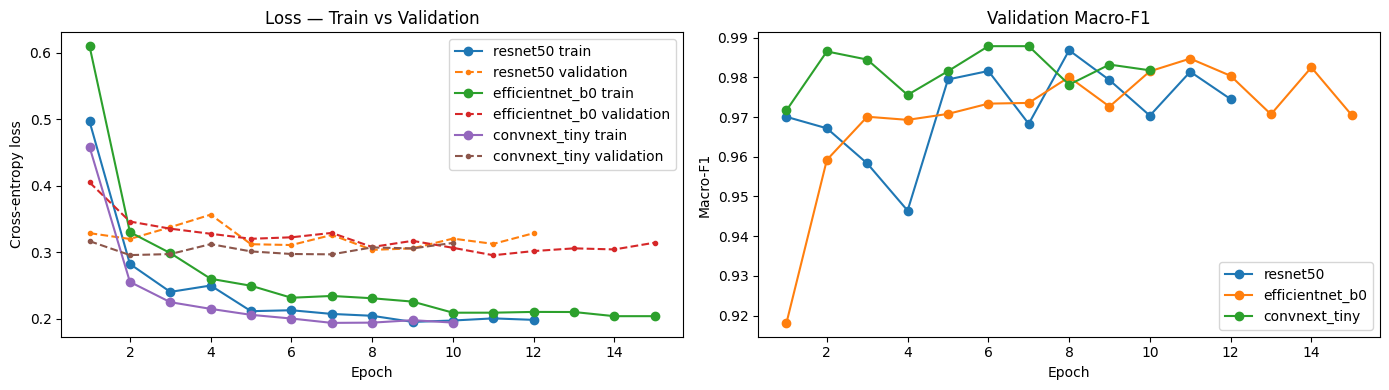

Courbes sauvegardées : /kaggle/working/olive_cad_outputs/training_curves.png


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for model_name in ("resnet50", "efficientnet_b0", "convnext_tiny"):
    history_df = pd.read_csv(OUTPUT_DIR / f"history_{model_name}.csv")
    axes[0].plot(
        history_df["epoch"], history_df["train_loss"],
        marker="o", label=f"{model_name} train"
    )
    axes[0].plot(
        history_df["epoch"], history_df["val_loss"],
        marker=".", linestyle="--", label=f"{model_name} validation"
    )
    axes[1].plot(
        history_df["epoch"], history_df["val_macro_f1"],
        marker="o", label=model_name
    )

axes[0].set_title("Loss — Train vs Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].set_title("Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()

plt.tight_layout()
curve_path = OUTPUT_DIR / "training_curves.png"
plt.savefig(curve_path, dpi=160, bbox_inches="tight")
plt.show()
print("Courbes sauvegardées :", curve_path)

## 21. Évaluation finale sur Test — une seule fois

Le modèle a déjà été choisi sur Validation. La cellule suivante évalue ce modèle gagnant sur Test, une seule fois. Ne pas modifier les hyperparamètres après avoir observé les résultats du Test.

Modèle sélectionné : convnext_tiny

Métriques Test :
accuracy            : 0.9926
precision_macro     : 0.9898
recall_macro        : 0.9862
macro_f1            : 0.9880
weighted_f1         : 0.9926
loss                : 0.0760


,precision,recall,f1-score,support
aculus_olearius,0.983871,0.968254,0.976000,63.000000
healthy,0.995050,0.995050,0.995050,404.000000
peacock_spot,0.990476,0.995215,0.992840,209.000000
accuracy,0.992604,0.992604,0.992604,0.992604
macro avg,0.989799,0.986173,0.987963,676.000000
weighted avg,0.992594,0.992604,0.992591,676.000000


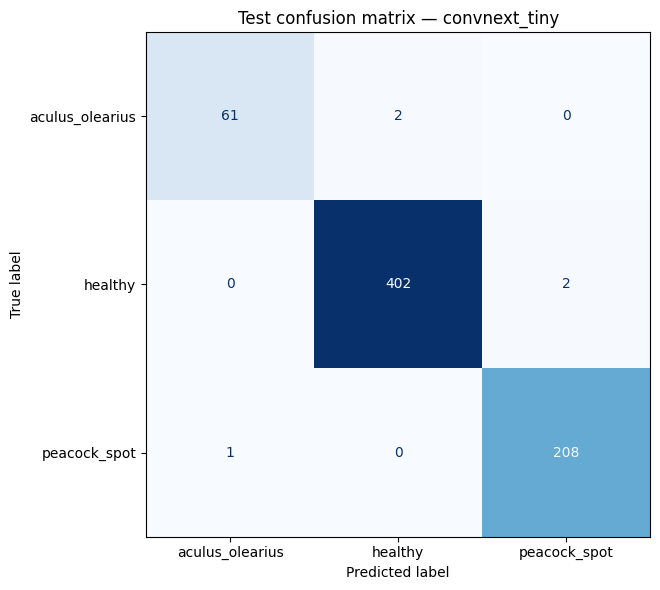

In [25]:
checkpoint = torch.load(WINNER_CHECKPOINT, map_location="cpu")
final_model, _, _ = build_model(WINNER_NAME, pretrained=False)
final_model.load_state_dict(checkpoint["state_dict"])
final_model = final_model.to(DEVICE).eval()

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

test_metrics, y_true, y_pred, y_prob = run_evaluation(
    final_model, test_loader, criterion
)

print("Modèle sélectionné :", WINNER_NAME)
print("\nMétriques Test :")
for key, value in test_metrics.items():
    print(f"{key:20s}: {value:.4f}")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(OUTPUT_DIR / "test_classification_report.csv")

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Test confusion matrix — {WINNER_NAME}")
plt.tight_layout()
cm_path = OUTPUT_DIR / "test_confusion_matrix.png"
plt.savefig(cm_path, dpi=180, bbox_inches="tight")
plt.show()

final_metrics = {
    "selected_model": WINNER_NAME,
    "best_validation_macro_f1": float(comparison.iloc[0]["best_val_macro_f1"]),
    **{f"test_{key}": float(value) for key, value in test_metrics.items()},
}
pd.DataFrame([final_metrics]).to_csv(
    OUTPUT_DIR / "final_metrics.csv", index=False
)
with open(OUTPUT_DIR / "final_metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_metrics, file, indent=2, ensure_ascii=False)

## 22. Latence d'inférence

In [26]:
# Mesure batch=1 sur le GPU actif ; inclut la synchronisation CUDA.
sample_tensor, _ = test_dataset[0]
input_tensor = sample_tensor.unsqueeze(0).to(DEVICE)

for _ in range(10):
    with torch.no_grad(), autocast_context():
        _ = final_model(input_tensor)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

timings_ms = []
for _ in range(100):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad(), autocast_context():
        _ = final_model(input_tensor)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    timings_ms.append((time.perf_counter() - start) * 1000)

latency = {
    "mean_ms": float(np.mean(timings_ms)),
    "p50_ms": float(np.percentile(timings_ms, 50)),
    "p95_ms": float(np.percentile(timings_ms, 95)),
}

print("Latence batch=1 :")
for key, value in latency.items():
    print(f"{key:12s}: {value:.2f} ms")

final_metrics.update({
    "inference_latency_mean_ms": latency["mean_ms"],
    "inference_latency_p50_ms": latency["p50_ms"],
    "inference_latency_p95_ms": latency["p95_ms"],
})
with open(OUTPUT_DIR / "final_metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_metrics, file, indent=2, ensure_ascii=False)

Latence batch=1 :
mean_ms     : 8.76 ms
p50_ms      : 8.63 ms
p95_ms      : 9.50 ms


## 23. Explicabilité — Grad-CAM

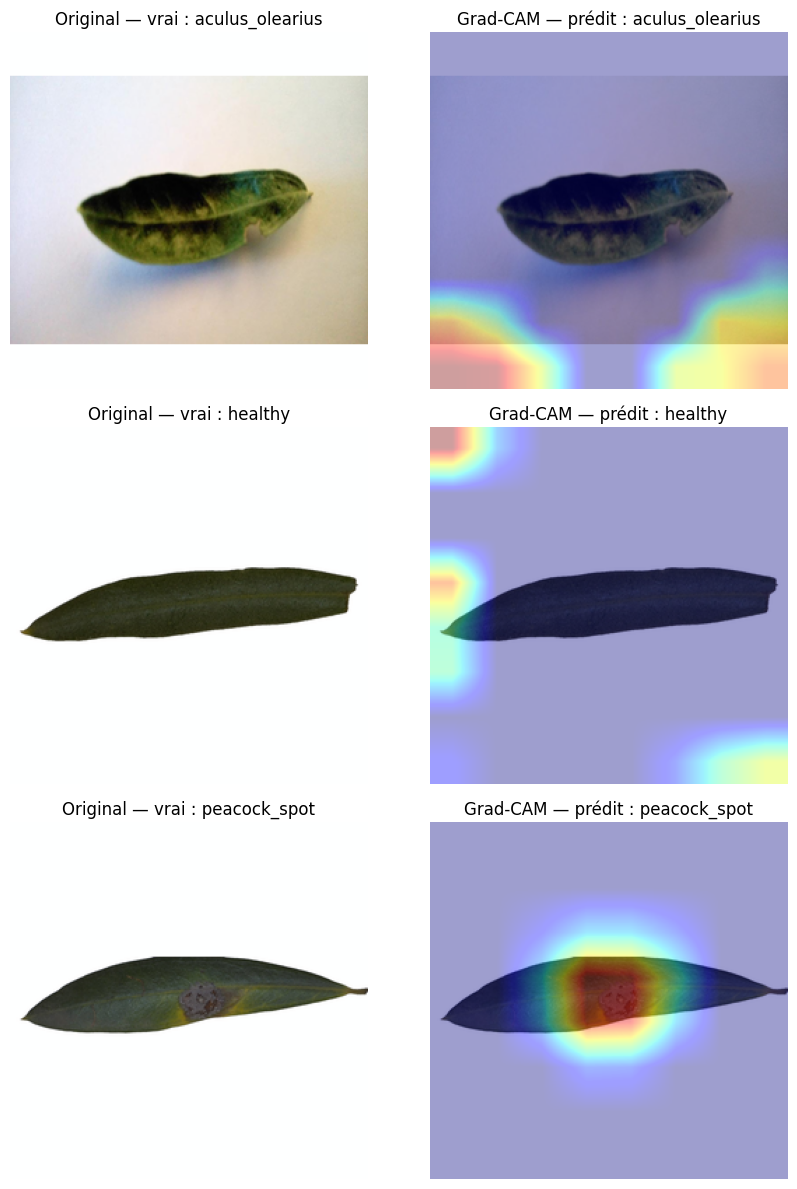

Grad-CAM sauvegardé : /kaggle/working/olive_cad_outputs/gradcam_examples.png


In [27]:
def find_last_conv_layer(model):
    last_conv = None
    for module in model.modules():
        if isinstance(module, nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise RuntimeError("Aucune couche convolutionnelle trouvée.")
    return last_conv

def generate_gradcam(model, input_tensor, target_layer=None, class_idx=None):
    model.eval()
    target_layer = target_layer or find_last_conv_layer(model)
    activations, gradients = {}, {}

    def forward_hook(module, inputs, output):
        activations["value"] = output
        output.register_hook(
            lambda grad: gradients.__setitem__("value", grad)
        )

    handle = target_layer.register_forward_hook(forward_hook)
    model.zero_grad(set_to_none=True)

    logits = model(input_tensor)
    if class_idx is None:
        class_idx = int(logits.argmax(dim=1).item())

    logits[:, class_idx].sum().backward()

    weights = gradients["value"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu(
        (weights * activations["value"]).sum(dim=1, keepdim=True)
    )
    cam = F.interpolate(
        cam,
        size=input_tensor.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    handle.remove()
    model.zero_grad(set_to_none=True)
    return cam.detach().cpu().numpy(), class_idx, logits.detach()

# Une image de test par classe ; indique la vraie classe et la classe prédite.
fig, axes = plt.subplots(len(class_names), 2, figsize=(9, 4 * len(class_names)))
axes = np.atleast_2d(axes)

for row, class_idx in enumerate(range(len(class_names))):
    candidates = [
        i for i, (_, label) in enumerate(test_dataset.samples)
        if label == class_idx
    ]
    if not candidates:
        continue

    image_tensor, true_label = test_dataset[candidates[0]]
    batch = image_tensor.unsqueeze(0).to(DEVICE)
    cam, predicted_idx, logits = generate_gradcam(final_model, batch)

    mean = np.asarray(IMAGENET_MEAN).reshape(1, 1, 3)
    std = np.asarray(IMAGENET_STD).reshape(1, 1, 3)
    base = np.clip(
        image_tensor.permute(1, 2, 0).numpy() * std + mean, 0, 1
    )
    heatmap = plt.get_cmap("jet")(cam)[..., :3]
    overlay = np.clip(0.62 * base + 0.38 * heatmap, 0, 1)
    predicted_label = class_names[int(predicted_idx)]

    axes[row, 0].imshow(base)
    axes[row, 0].set_title(f"Original — vrai : {class_names[true_label]}")
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"Grad-CAM — prédit : {predicted_label}")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
gradcam_path = OUTPUT_DIR / "gradcam_examples.png"
plt.savefig(gradcam_path, dpi=180, bbox_inches="tight")
plt.show()
print("Grad-CAM sauvegardé :", gradcam_path)

## 24. MLflow Model Registry

In [28]:
registry_status = "registered"

try:
    with mlflow.start_run(run_name=f"register_best_{WINNER_NAME}"):
        mlflow.log_param("selected_architecture", WINNER_NAME)
        mlflow.log_param("selection_metric", "validation_macro_f1")
        mlflow.log_metric(
            "validation_macro_f1",
            float(comparison.iloc[0]["best_val_macro_f1"])
        )
        mlflow.log_metrics({
            f"test_{key}": float(value)
            for key, value in test_metrics.items()
        })
        mlflow.pytorch.log_model(
            pytorch_model=final_model,
            artifact_path="model",
            registered_model_name="OLIVE-CAD-Classifier",
        )
except Exception as exc:
    registry_status = f"warning: {type(exc).__name__}: {exc}"
    print("Registry MLflow indisponible :", registry_status)

print("Registry status :", registry_status)
final_metrics["mlflow_registry_status"] = registry_status

2026/11/17 21:03:24 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/17 21:03:43 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.26.0+cu130) contains a local version label (+cu130). MLflow logged a pip requirement for this package as 'torchvision==0.26.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/17 21:03:43 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Registry status : registered


Successfully registered model 'OLIVE-CAD-Classifier'.
Created version '1' of model 'OLIVE-CAD-Classifier'.


## 25. Export ONNX et vérification

In [29]:
onnx_path = OUTPUT_DIR / "olive_cad_classifier.onnx"
onnx_status = "not_exported"

dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)

try:
    torch.onnx.export(
        final_model,
        dummy_input,
        str(onnx_path),
        input_names=["image"],
        output_names=["logits"],
        dynamic_axes={
            "image": {0: "batch_size"},
            "logits": {0: "batch_size"},
        },
        opset_version=17,
        do_constant_folding=True,
        dynamo=False,
    )
    onnx_status = "exported"
    print("ONNX exporté :", onnx_path)
except Exception as exc:
    print("Export ONNX échoué :", repr(exc))
    print("Le checkpoint PyTorch reste disponible.")

# Vérification ONNX Runtime si la bibliothèque est disponible.
if onnx_status == "exported":
    try:
        import onnxruntime as ort
        session = ort.InferenceSession(
            str(onnx_path),
            providers=["CPUExecutionProvider"],
        )
        input_array = dummy_input.detach().cpu().numpy().astype(np.float32)

        with torch.no_grad():
            torch_output = final_model(dummy_input).detach().cpu().numpy()

        onnx_output = session.run(
            ["logits"], {"image": input_array}
        )[0]

        max_abs_diff = float(np.max(np.abs(torch_output - onnx_output)))
        onnx_status = "verified" if max_abs_diff < 1e-3 else "review_difference"
        print("ONNX max absolute difference :", max_abs_diff)
    except ImportError:
        onnx_status = "exported_not_runtime_verified"
        print("onnxruntime absent : export réalisé, vérification non effectuée.")
    except Exception as exc:
        onnx_status = f"runtime_check_warning: {type(exc).__name__}"
        print("Vérification ONNX Runtime non terminée :", repr(exc))

final_metrics["onnx_status"] = onnx_status

/tmp/ipykernel_117/621248738.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX exporté : /kaggle/working/olive_cad_outputs/olive_cad_classifier.onnx
onnxruntime absent : export réalisé, vérification non effectuée.


## 26. Sauvegarde des livrables

In [30]:
# Checkpoint portable + métadonnées d'inférence
final_checkpoint_path = OUTPUT_DIR / "olive_cad_best_model.pth"
shutil.copy2(WINNER_CHECKPOINT, final_checkpoint_path)

with open(OUTPUT_DIR / "class_names.json", "w", encoding="utf-8") as file:
    json.dump(
        {"classes": class_names, "class_to_idx": class_to_idx},
        file, indent=2, ensure_ascii=False
    )

run_summary = {
    "project": "OLIVE-CAD",
    "dataset_version": "grouped_v1",
    "selected_model": WINNER_NAME,
    "selection_rule": "highest validation macro-F1",
    "classes": class_names,
    "image_size": IMAGE_SIZE,
    "normalization": {
        "mean": IMAGENET_MEAN,
        "std": IMAGENET_STD,
    },
    "seed": SEED,
    "phash_max_distance": PHASH_MAX_DISTANCE,
    "images_used": len(manifest),
    "images_quarantined": len(quarantine_df),
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "validation_comparison": comparison.to_dict(orient="records"),
    "final_metrics": final_metrics,
}

with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as file:
    json.dump(run_summary, file, indent=2, ensure_ascii=False)

# Copier le manifeste du nouveau split vers le dossier de livrables.
manifest_source = GROUPED_DATASET_DIR / "manifest.csv"
if manifest_source.exists():
    shutil.copy2(manifest_source, OUTPUT_DIR / "grouped_dataset_manifest.csv")

# Les autres rapports sont déjà enregistrés directement dans OUTPUT_DIR.
required_reports = [
    "near_duplicate_candidates.csv",
    "phash_group_audit.csv",
    "quarantined_label_conflicts.csv",
    "initial_inventory.csv",
    "grouped_split_distribution.csv",
    "training_config.json",
    "three_model_comparison_validation.csv",
    "test_classification_report.csv",
    "final_metrics.csv",
    "final_metrics.json",
    "training_curves.png",
    "test_confusion_matrix.png",
    "gradcam_examples.png",
]
missing_reports = [
    name for name in required_reports
    if not (OUTPUT_DIR / name).exists()
]
if missing_reports:
    print("Rapports non générés :", missing_reports)

# Enregistrer la base MLflow et ses artefacts de tracking.
if MLFLOW_DB.exists():
    shutil.copy2(MLFLOW_DB, OUTPUT_DIR / "olive_cad_mlflow.db")
if MLFLOW_ARTIFACTS.exists():
    shutil.copytree(
        MLFLOW_ARTIFACTS,
        OUTPUT_DIR / "mlflow_artifacts",
        dirs_exist_ok=True,
    )

archive_base = WORK_DIR / "OLIVE-CAD-results-grouped-v1"
archive_path = shutil.make_archive(
    str(archive_base), "zip", root_dir=OUTPUT_DIR
)

print("Livrables sauvegardés :")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

print("\\nArchive à télécharger :", archive_path)
print("Taille (MB) :", round(Path(archive_path).stat().st_size / (1024**2), 2))

Livrables sauvegardés :
 - best_convnext_tiny.pth
 - best_efficientnet_b0.pth
 - best_resnet50.pth
 - class_names.json
 - final_metrics.csv
 - final_metrics.json
 - gradcam_examples.png
 - grouped_dataset_manifest.csv
 - grouped_split_distribution.csv
 - history_convnext_tiny.csv
 - history_efficientnet_b0.csv
 - history_resnet50.csv
 - initial_inventory.csv
 - mlflow_artifacts
 - near_duplicate_candidates.csv
 - olive_cad_best_model.pth
 - olive_cad_classifier.onnx
 - olive_cad_mlflow.db
 - phash_group_audit.csv
 - quarantined_label_conflicts.csv
 - run_summary.json
 - test_classification_report.csv
 - test_confusion_matrix.png
 - three_model_comparison_validation.csv
 - training_config.json
 - training_curves.png
\nArchive à télécharger : /kaggle/working/OLIVE-CAD-results-grouped-v1.zip
Taille (MB) : 689.75


## 27. Résumé final

In [31]:
summary_rows = [
    ("Dataset source", str(DATASET_ROOT)),
    ("Images retenues", len(manifest)),
    ("Images en quarantaine", len(quarantine_df)),
    ("Modèle sélectionné", WINNER_NAME),
    ("Validation Macro-F1", round(float(comparison.iloc[0]["best_val_macro_f1"]), 4)),
    ("Test Accuracy", round(float(test_metrics["accuracy"]), 4)),
    ("Test Macro-F1", round(float(test_metrics["macro_f1"]), 4)),
    ("ONNX", onnx_status),
    ("MLflow Registry", registry_status),
    ("Archive", str(archive_path)),
]
display(pd.DataFrame(summary_rows, columns=["Élément", "Résultat"]))
print("\nExécution terminée. Vérifie les rapports de quarantaine avant d'interpréter les métriques.")

,Élément,Résultat
0,Dataset source,/kaggle/working/olive_cad_grouped_v1
1,Images retenues,4522
2,Images en quarantaine,43
3,Modèle sélectionné,convnext_tiny
4,Validation Macro-F1,0.9878
5,Test Accuracy,0.9926
6,Test Macro-F1,0.988
7,ONNX,exported_not_runtime_verified
8,MLflow Registry,registered
9,Archive,/kaggle/working/OLIVE-CAD-results-grouped-v1.zip



Exécution terminée. Vérifie les rapports de quarantaine avant d'interpréter les métriques.
